# E1: YOLO11s-pose trained on filtered ViTPose teacher labels, with an ignore-aware loss

ViTPose-L SwimXYZ is used **offline as a teacher only** (its E0 predictions are reused; it is not run or deployed here).
Two changes against the earlier distillation run:
1. **Labels**: a ViTPose keypoint is used only if confident (>= 0.7), consistent on the mirrored image and stable from
   the previous frame. All other keypoints are *unknown*.
2. **Loss**: unknown keypoints are ignored (patched Ultralytics loss), instead of being trained as "absent". This
   removes the cause of the lower-body confidence collapse seen before.

Splits: held-out blocks 2/13/15/16 (all E3 and test-27 frames) are never trained on; two other blocks are validation.
All evaluation here is **agreement** (with AI visual references on E3, with ViTPose on test-27), not accuracy.


## 0. Inputs

In [27]:
# 0. Drive and inputs
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
DRIVE = Path('/content/drive/MyDrive')
OUTD = DRIVE / 'pose_baseline'
E1 = OUTD / 'e1'
E1.mkdir(exist_ok=True)
PRED = OUTD / 'e0' / 'e0_predictions.jsonl'
DS_ZIP = DRIVE / 'datasets (1).zip'
YOLO_PT = OUTD / 'models' / 'yolo11s-pose.pt'
DIST_PT = OUTD / 'runs_pose' / 'yolo11s_pose_distill_960' / 'weights' / 'best.pt'
E3_REF = OUTD / 'e3' / 'pose_gt_e3.json'
E3_ZIP = OUTD / 'e3' / 'e3_set.zip'
T27_REF = OUTD / 'ai_reference' / 'ai_reference_unverified_test27.json'
SET_ZIP = OUTD / 'pose_annotation_set_v2.zip'
for f in (PRED, DS_ZIP, YOLO_PT, DIST_PT, E3_REF, E3_ZIP, T27_REF, SET_ZIP):
    print('OK     ' if f.is_file() else 'MISSING', f)
!nvidia-smi --query-gpu=name,memory.total --format=csv


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK      /content/drive/MyDrive/pose_baseline/e0/e0_predictions.jsonl
OK      /content/drive/MyDrive/datasets (1).zip
OK      /content/drive/MyDrive/pose_baseline/models/yolo11s-pose.pt
OK      /content/drive/MyDrive/pose_baseline/runs_pose/yolo11s_pose_distill_960/weights/best.pt
OK      /content/drive/MyDrive/pose_baseline/e3/pose_gt_e3.json
OK      /content/drive/MyDrive/pose_baseline/e3/e3_set.zip
OK      /content/drive/MyDrive/pose_baseline/ai_reference/ai_reference_unverified_test27.json
OK      /content/drive/MyDrive/pose_baseline/pose_annotation_set_v2.zip
name, memory.total [MiB]
Tesla T4, 15360 MiB


## 1. Install

In [28]:
# 1. Install
!pip -q install ultralytics
import ultralytics
print('ultralytics', ultralytics.__version__)
!mkdir -p /content/pose_tools


ultralytics 8.4.220


## 2. Tools (generated from `python_scripts/pose/`)

In [29]:
%%writefile /content/pose_tools/pose_common.py
"""Shared helpers for the pose proposal / zero-shot tools (no project imports).

Top-down model contract (from the ViTPose-L SwimXYZ model card): input (N, 3, 256, 192) float32,
ImageNet-normalised RGB crop; output (N, 17, 64, 48) heatmaps in COCO-17 order.
Pure-numpy parts (box->crop parameters, heatmap decoding, PCK) are testable without weights.
"""
from __future__ import annotations

import math
from typing import Any

import numpy as np

COCO17 = ["nose", "left_eye", "right_eye", "left_ear", "right_ear", "left_shoulder", "right_shoulder",
          "left_elbow", "right_elbow", "left_wrist", "right_wrist", "left_hip", "right_hip",
          "left_knee", "right_knee", "left_ankle", "right_ankle"]
UPPER_BODY = [0, 5, 6, 7, 8, 9, 10]  # nose, shoulders, elbows, wrists
COCO_SKELETON = [[16, 14], [14, 12], [17, 15], [15, 13], [12, 13], [6, 12], [7, 13], [6, 7], [6, 8],
                 [7, 9], [8, 10], [9, 11], [2, 3], [1, 2], [1, 3], [2, 4], [3, 5], [4, 6], [5, 7]]
IN_W, IN_H = 192, 256
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def crop_params(box_xyxy: tuple[float, float, float, float], scale: float = 1.25) -> tuple[float, float, float]:
    """Return (x0, y0, s) of the crop window: window covers IN_W/s x IN_H/s pixels, box centred, padded."""
    x1, y1, x2, y2 = box_xyxy
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    bw, bh = max(x2 - x1, 1.0) * scale, max(y2 - y1, 1.0) * scale
    if bw / bh > IN_W / IN_H:
        bh = bw * IN_H / IN_W
    else:
        bw = bh * IN_W / IN_H
    s = IN_W / bw
    return cx - bw / 2, cy - bh / 2, s


def preprocess(frame_bgr: np.ndarray, box_xyxy: tuple[float, float, float, float]
               ) -> tuple[np.ndarray, tuple[float, float, float]]:
    import cv2  # lazy: Colab has it

    x0, y0, s = crop_params(box_xyxy)
    m = np.array([[s, 0, -x0 * s], [0, s, -y0 * s]], dtype=np.float32)
    crop = cv2.warpAffine(frame_bgr, m, (IN_W, IN_H), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))
    rgb = crop[:, :, ::-1].astype(np.float32) / 255.0
    rgb = (rgb - MEAN) / STD
    return rgb.transpose(2, 0, 1)[None], (x0, y0, s)


def decode_heatmaps(hm: np.ndarray, params: tuple[float, float, float]) -> np.ndarray:
    """hm: (17, H, W) -> (17, 3) [x, y, score] in image pixels (argmax, +quarter-pixel shift)."""
    k, h, w = hm.shape
    x0, y0, s = params
    out = np.zeros((k, 3), dtype=np.float32)
    for i in range(k):
        flat = int(np.argmax(hm[i]))
        iy, ix = divmod(flat, w)
        score = float(hm[i, iy, ix])
        fx, fy = float(ix), float(iy)
        if 0 < ix < w - 1:
            fx += 0.25 * np.sign(hm[i, iy, ix + 1] - hm[i, iy, ix - 1])
        if 0 < iy < h - 1:
            fy += 0.25 * np.sign(hm[i, iy + 1, ix] - hm[i, iy - 1, ix])
        cx, cy = (fx + 0.5) * IN_W / w, (fy + 0.5) * IN_H / h  # crop pixels
        out[i] = (cx / s + x0, cy / s + y0, score)
    return out


class OnnxVitPose:
    """Top-down ONNX pose model (ViTPose-L SwimXYZ export). Input name is read from the graph."""

    def __init__(self, path: str, providers: list[str] | None = None) -> None:
        import onnxruntime as ort

        self.sess = ort.InferenceSession(path, providers=providers or ["CUDAExecutionProvider",
                                                                         "CPUExecutionProvider"])
        self.input_name = self.sess.get_inputs()[0].name

    def predict(self, frame_bgr: np.ndarray, boxes: list[tuple[float, float, float, float]]) -> list[np.ndarray]:
        res = []
        for b in boxes:
            x, params = preprocess(frame_bgr, b)
            hm = self.sess.run(None, {self.input_name: x})[0][0]
            res.append(decode_heatmaps(hm, params))
        return res


def iou(a: tuple[float, ...], b: tuple[float, ...]) -> float:
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def pck(pred: np.ndarray, gt: np.ndarray, box_xyxy: tuple[float, ...], thr: float,
        idx: list[int] | None = None) -> tuple[int, int]:
    """(correct, total) over GT keypoints with visibility > 0. Normaliser: longer side of the GT box."""
    norm = max(box_xyxy[2] - box_xyxy[0], box_xyxy[3] - box_xyxy[1], 1.0)
    ok = tot = 0
    for i in idx if idx is not None else range(len(gt)):
        if gt[i][2] <= 0:
            continue
        tot += 1
        if math.hypot(pred[i][0] - gt[i][0], pred[i][1] - gt[i][1]) <= thr * norm:
            ok += 1
    return ok, tot


def confident_upper(pred: np.ndarray, min_conf: float = 0.5) -> int:
    return int(sum(1 for i in UPPER_BODY if pred[i][2] >= min_conf))


def as_info(**kw: Any) -> dict[str, Any]:
    return kw


Overwriting /content/pose_tools/pose_common.py


In [30]:
%%writefile /content/pose_tools/zero_shot_eval.py
"""Zero-shot comparison of pose models on HAND-CORRECTED frames (CVAT export, COCO keypoints 1.0).

Metrics (all on GT keypoints with visibility > 0; normaliser = longer side of the GT box):
  PCK@0.05 / 0.1 / 0.2 on upper body (nose, shoulders, elbows, wrists) and on all 17,
  share of frames with >= 3 confident (>=0.5) upper-body keypoints, latency per person.
Models (any subset):
  --vitpose-onnx   ViTPose-L SwimXYZ ONNX, top-down on the GT box
  --yolo-pose      Ultralytics pose weights, full frame; the prediction with best IoU to the GT box is used
Only run on the `real_val` frames; select with --split-manifest + --split real_val. Report per camera type via --group.
"""
from __future__ import annotations

import argparse
import csv
import json
import time
from pathlib import Path

import cv2
import numpy as np

from pose_common import UPPER_BODY, OnnxVitPose, confident_upper, iou, pck

THRS = (0.05, 0.1, 0.2)
FLIP_IDX = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]  # COCO-17 left <-> right


def load_gt(coco_path: Path) -> dict[str, tuple[np.ndarray, tuple[float, float, float, float]]]:
    d = json.loads(coco_path.read_text(encoding="utf-8"))
    names = {i["id"]: i["file_name"] for i in d["images"]}
    out = {}
    for a in d["annotations"]:
        k = np.array(a["keypoints"], dtype=np.float32).reshape(-1, 3)
        if k.shape[0] != 17:
            raise SystemExit(f"annotation {a['id']} has {k.shape[0]} keypoints, expected 17 (COCO order)")
        x, y, w, h = a["bbox"]
        out[Path(names[a["image_id"]]).name] = (k, (x, y, x + w, y + h))
    return out


def run_vitpose(model: OnnxVitPose, img: np.ndarray, box: tuple[float, ...]) -> np.ndarray:
    return model.predict(img, [box])[0]


def run_yolo(model, img: np.ndarray, box: tuple[float, ...]) -> np.ndarray | None:  # noqa: ANN001
    res = model.predict(img, verbose=False)[0]
    if res.keypoints is None or len(res.boxes) == 0:
        return None
    best, best_iou = None, 0.0
    for i, b in enumerate(res.boxes.xyxy.cpu().numpy()):
        v = iou(tuple(b), box)
        if v > best_iou:
            best, best_iou = i, v
    if best is None or best_iou < 0.3:
        return None
    xy = res.keypoints.xy[best].cpu().numpy()
    cf = res.keypoints.conf[best].cpu().numpy() if res.keypoints.conf is not None else np.ones(17)
    return np.concatenate([xy, cf[:, None]], axis=1)


def main() -> int:
    ap = argparse.ArgumentParser(description=__doc__)
    ap.add_argument("--gt", type=Path, required=True, help="CVAT export (COCO keypoints 1.0) json")
    ap.add_argument("--images", type=Path, required=True, help="folder with the images of the set")
    ap.add_argument("--manifest", type=Path, help="manifest.csv, to restrict to --split")
    ap.add_argument("--split", default="real_val")
    ap.add_argument("--group", default="", help="substring of image name defining a camera group, e.g. 'ddt'")
    ap.add_argument("--vitpose-onnx", type=str)
    ap.add_argument("--yolo-pose", type=str)
    ap.add_argument("--out", type=Path, default=Path("zero_shot_results.csv"))
    ap.add_argument("--boxes-from-manifest", action="store_true",
                    help="use the manifest person boxes (x1..y2) instead of the GT bbox. Use for CVAT exports, whose "
                         "bbox is fitted tightly around the annotated points")
    a = ap.parse_args()

    if not a.gt.is_file():
        raise SystemExit(f"GT file not found: {a.gt}. Export the corrected real_val frames from CVAT first "
                         "(see docs/POSE_ANNOTATION_GUIDE.md); this step cannot run before that.")
    gt = load_gt(a.gt)
    if a.boxes_from_manifest:
        if not a.manifest:
            raise SystemExit("--boxes-from-manifest needs --manifest")
        mboxes = {Path(r["image"]).name: tuple(float(r[k]) for k in ("x1", "y1", "x2", "y2"))
                  for r in csv.DictReader(open(a.manifest, encoding="utf-8"))}
        gt = {n: (k, mboxes[n]) for n, (k, _) in gt.items() if n in mboxes}
    names = set(gt)
    if a.manifest:
        names &= {Path(r["image"]).name for r in csv.DictReader(open(a.manifest, encoding="utf-8"))
                  if r["split"] == a.split}
    if a.group:
        names = {n for n in names if a.group in n}
    names = sorted(names)
    if not names:
        raise SystemExit("no frames selected: check --split / --group / file names")
    print(f"{len(names)} frames, split={a.split}, group={a.group or 'all'}")

    runners = {}
    if a.vitpose_onnx:
        m = OnnxVitPose(a.vitpose_onnx)
        runners["vitpose_swimxyz"] = lambda im, b: run_vitpose(m, im, b)
    if a.yolo_pose:
        from ultralytics import YOLO

        y = YOLO(a.yolo_pose)
        runners[Path(a.yolo_pose).stem] = lambda im, b: run_yolo(y, im, b)
    if not runners:
        raise SystemExit("give --vitpose-onnx and/or --yolo-pose")

    rows = []
    for mname, fn in runners.items():
        acc = {(s, t): [0, 0] for s in ("upper", "all") for t in THRS}
        acc_sw = {(s, t): [0, 0] for s in ("upper", "all") for t in THRS}
        n_conf3 = n_missing = n_swapped = 0
        times = []
        for n in names:
            img = cv2.imread(str(a.images / n))
            k, box = gt[n]
            t0 = time.perf_counter()
            pred = fn(img, box)
            times.append((time.perf_counter() - t0) * 1000)
            if pred is None:
                n_missing += 1
                pred = np.zeros((17, 3), dtype=np.float32)
                pred[:, :2] = -1e6
            n_conf3 += confident_upper(pred) >= 3
            # swap-tolerant: one left/right decision per frame (whole skeleton mirrored in labels, positions kept),
            # chosen by the larger PCK@0.2 over all keypoints; ties keep the original labelling
            swapped = pred[FLIP_IDX]
            use_swap = pck(swapped, k, box, 0.2)[0] > pck(pred, k, box, 0.2)[0]
            n_swapped += use_swap
            best = swapped if use_swap else pred
            for t in THRS:
                for s, idx in (("upper", UPPER_BODY), ("all", None)):
                    ok, tot = pck(pred, k, box, t, idx)
                    acc[(s, t)][0] += ok
                    acc[(s, t)][1] += tot
                    ok2, _ = pck(best, k, box, t, idx)
                    acc_sw[(s, t)][0] += ok2
                    acc_sw[(s, t)][1] += tot
        row = {"model": mname, "frames": len(names), "no_prediction": n_missing,
               "frames_ge3_confident_upper": round(n_conf3 / len(names), 3),
               "latency_ms_median_per_person": round(float(np.median(times)), 1),
               "frames_better_with_lr_swap": n_swapped}
        for (s, t), (ok, tot) in acc.items():
            row[f"PCK@{t}_{s}"] = round(ok / tot, 3) if tot else None
        for (s, t), (ok, tot) in acc_sw.items():
            row[f"PCK@{t}_{s}_swaptol"] = round(ok / tot, 3) if tot else None
        rows.append(row)
        print(row)
    with open(a.out, "w", newline="", encoding="utf-8") as f:
        wr = csv.DictWriter(f, fieldnames=list(rows[0]))
        wr.writeheader()
        wr.writerows(rows)
    print("wrote", a.out)
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


Overwriting /content/pose_tools/zero_shot_eval.py


In [31]:
%%writefile /content/pose_tools/build_e1_dataset.py
"""E1: YOLO-pose dataset from filtered ViTPose teacher labels (offline teacher only; ViTPose is never deployed).

Source: E0 predictions (`e0_predictions.jsonl`: ViTPose on every frame and on its mirrored copy) plus the dataset's own
person boxes. A ViTPose keypoint becomes a training label (v=2) only if
  confidence >= --conf  AND  flip error <= --flip-max  AND  (no previous frame, or jump <= --jump-max)
(distances as fractions of the box's longer side). Every other keypoint is UNKNOWN:
  train labels: v=1 (ignored by the patched loss, see ignore_aware_pose_loss.py), placed at the box centre so that
                augmentation does not push it outside the image (which would make Ultralytics set v=0)
  val labels:   v=0 (Ultralytics' OKS metric treats v>0 as labelled)
Splits: held-out blocks (2, 13, 15, 16; the E3/test frames come from them) are never used.
Whole frame-index blocks (about --val-frac of the frames) become the validation split; no neighbouring frames are
shared between train and validation.
Provenance of every label: vitpose_teacher_filtered (pseudo-label, not ground truth).
"""
from __future__ import annotations

import argparse
import csv
import json
import random
import shutil
from collections import Counter
from pathlib import Path

import numpy as np

FLIP_IDX = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11, 14, 13, 16, 15]
COCO17 = ["nose", "left_eye", "right_eye", "left_ear", "right_ear", "left_shoulder", "right_shoulder", "left_elbow",
          "right_elbow", "left_wrist", "right_wrist", "left_hip", "right_hip", "left_knee", "right_knee", "left_ankle",
          "right_ankle"]


def main() -> int:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--root", type=Path, required=True, help="dataset root with images/{train,val}, labels/{train,val}")
    ap.add_argument("--pred", type=Path, required=True, help="E0 predictions JSONL")
    ap.add_argument("--out", type=Path, required=True)
    ap.add_argument("--conf", type=float, default=0.7)
    ap.add_argument("--flip-max", type=float, default=0.05)
    ap.add_argument("--jump-max", type=float, default=0.25)
    ap.add_argument("--min-points", type=int, default=3, help="drop frames with fewer confident points")
    ap.add_argument("--val-frac", type=float, default=0.15,
                    help="target share of non-held-out frames used for validation (whole blocks)")
    ap.add_argument("--seed", type=int, default=42)
    a = ap.parse_args()

    recs = sorted((json.loads(ln) for ln in a.pred.read_text().splitlines() if ln.strip()), key=lambda r: r["idx"])
    by_idx = {r["idx"]: r for r in recs}
    pool = [r for r in recs if not r["heldout"]]
    counts = Counter(r["block"] for r in pool)
    # whole blocks to validation until ~val_frac of the frames; skip blocks that alone overshoot 1.5x the target
    target = a.val_frac * len(pool)
    cands = [b for b, n in counts.items() if n >= 50 and n <= 1.5 * target]
    random.Random(a.seed).shuffle(cands)
    val_blocks, n_val = set(), 0
    for b in cands:
        if n_val >= target:
            break
        val_blocks.add(b)
        n_val += counts[b]
    if not val_blocks:
        val_blocks = {min(counts, key=counts.get)}

    for sp in ("train", "val"):
        (a.out / "images" / sp).mkdir(parents=True, exist_ok=True)
        (a.out / "labels" / sp).mkdir(parents=True, exist_ok=True)
    kept = Counter()
    dropped = 0
    lab = {sp: np.zeros(17) for sp in ("train", "val")}
    man = open(a.out / "e1_manifest.csv", "w", newline="", encoding="utf-8")
    wr = csv.writer(man)
    wr.writerow(["image", "split", "block", "frame", "confident_points", "label_provenance"])
    for r in pool:
        sp = "val" if r["block"] in val_blocks else "train"
        w, h = r["W"], r["H"]
        x1, y1, x2, y2 = r["box"]
        size = max(x2 - x1, y2 - y1, 1.0)
        c = np.array([(x1 + x2) / 2, (y1 + y2) / 2])
        kv, kf = np.array(r["vit"]), np.array(r["vit_f"])
        prev = next((by_idx[r["idx"] - g] for g in (1, 2, 3) if r["idx"] - g in by_idx), None)
        vals, n_conf, good_idx = [0, (x1 + x2) / 2 / w, (y1 + y2) / 2 / h, (x2 - x1) / w, (y2 - y1) / h], 0, []
        for i in range(17):
            x, y, s = kv[i]
            good = s >= a.conf and kf[i][2] >= a.conf and np.hypot(*(kv[i][:2] - kf[i][:2])) / size <= a.flip_max
            if good and prev is not None and prev["vit"][i][2] >= a.conf:
                pc = np.array([(prev["box"][0] + prev["box"][2]) / 2, (prev["box"][1] + prev["box"][3]) / 2])
                jump = np.hypot(*((kv[i][:2] - c) - (np.array(prev["vit"][i][:2]) - pc))) / size
                good = jump <= a.jump_max
            good = good and 0 <= x < w and 0 <= y < h
            if good:
                vals += [x / w, y / h, 2]
                n_conf += 1
                good_idx.append(i)
            else:
                # unknown: placed at the box centre, not (0, 0). Ultralytics augmentation sets v=0 for any point
                # pushed outside the image, and (0, 0) usually is, which turned "unknown" into "absent" (E1 v1).
                vals += [(x1 + x2) / 2 / w, (y1 + y2) / 2 / h, 1 if sp == "train" else 0]
        if n_conf < a.min_points:
            dropped += 1
            continue
        src = a.root / "images" / r["folder"] / r["file"]
        shutil.copyfile(src, a.out / "images" / sp / r["file"])
        line = " ".join(str(int(v)) if i == 0 or (i >= 5 and (i - 5) % 3 == 2) else f"{v:.6f}"
                        for i, v in enumerate(vals))
        (a.out / "labels" / sp / (Path(r["file"]).stem + ".txt")).write_text(line + "\n")
        kept[sp] += 1
        lab[sp][good_idx] += 1  # coverage counted over kept frames only
        wr.writerow([r["file"], sp, r["block"], r["idx"], n_conf, "vitpose_teacher_filtered"])
    man.close()

    (a.out / "data.yaml").write_text(
        f"path: {a.out.as_posix()}\ntrain: images/train\nval: images/val\nkpt_shape: [17, 3]\n"
        f"flip_idx: {FLIP_IDX}\nnames:\n  0: person\n"
        "# train labels: v=2 confident ViTPose point, v=1 unknown (needs ignore_aware_pose_loss), v=0 absent\n"
        "# val labels: v=2 or 0. Provenance: vitpose_teacher_filtered (pseudo-labels, not ground truth)\n",
        encoding="utf-8")

    for sp in ("train", "val"):
        for lf in (a.out / "labels" / sp).glob("*.txt"):
            t = lf.read_text().split()
            assert len(t) == 56 and all(0.0 <= float(v) <= 1.0 for v in t[1:5]), lf
            assert set(float(v) for v in t[7::3]) <= ({0.0, 1.0, 2.0} if sp == "train" else {0.0, 2.0}), lf
    print(f"thresholds: conf >= {a.conf}, flip <= {a.flip_max}, jump <= {a.jump_max}, min points {a.min_points}")
    print(f"held-out blocks excluded; validation blocks: {sorted(val_blocks)}")
    print(f"frames kept: {dict(kept)}; dropped (< {a.min_points} confident points): {dropped}")
    print("keypoint          train coverage   val coverage   (fraction of kept frames with a confident label)")
    for i, nm in enumerate(COCO17):
        print(f"  {nm:16s} {lab['train'][i] / max(kept['train'], 1):.2f}            "
              f"{lab['val'][i] / max(kept['val'], 1):.2f}")
    return 0


if __name__ == "__main__":
    raise SystemExit(main())


Overwriting /content/pose_tools/build_e1_dataset.py


In [32]:
%%writefile /content/pose_tools/ignore_aware_pose_loss.py
"""Patch Ultralytics pose training so that UNKNOWN keypoints are ignored instead of trained as absent.

Why: in stock Ultralytics, `kpts_obj_loss = BCE(pred_conf, v != 0)` covers all 17 keypoints, so a keypoint written as
v=0 teaches the model "this joint is not there". Pseudo-labels have many uncertain points, and that taught the
distilled model to drop hips/knees/ankles (E0/E3 analysis, docs/POSE_SELF_SUPERVISED_RESEARCH.md).

Label convention while the patch is active (TRAINING labels only):
  v = 2  confident teacher point -> position loss + confidence target 1
  v = 1  unknown                 -> no loss at all
  v = 0  absent (e.g. pushed outside the image by augmentation) -> confidence target 0
Validation labels must use only 0 / 2 (Ultralytics' OKS metric treats v > 0 as labelled).

The patch rewrites three lines of `v8PoseLoss.calculate_keypoints_loss` and refuses to run if the installed
Ultralytics version does not contain them verbatim (tested on 8.3.40).
"""
from __future__ import annotations

import inspect
import textwrap

OLD_MASK = "kpt_mask = gt_kpt[..., 2] != 0 if gt_kpt.shape[-1] == 3 else torch.full_like(gt_kpt[..., 0], True)"
NEW_MASK = ("kpt_mask = gt_kpt[..., 2] == 2 if gt_kpt.shape[-1] == 3 else torch.full_like(gt_kpt[..., 0], True); "
            "known = gt_kpt[..., 2] != 1 if gt_kpt.shape[-1] == 3 else kpt_mask")
OLD_OBJ = "kpts_obj_loss = self.bce_pose(pred_kpt[..., 2], kpt_mask.float())  # keypoint obj loss"
NEW_OBJ = ("kpts_obj_loss = (torch.nn.functional.binary_cross_entropy_with_logits(pred_kpt[..., 2], "
           "kpt_mask.float(), reduction='none')[known].mean() if known.any() else pred_kpt[..., 2].sum() * 0.0)")
POS_LINE = "kpts_loss = self.keypoint_loss(pred_kpt, gt_kpt, kpt_mask, area)"  # unchanged; now uses v == 2


def apply() -> str:
    from ultralytics.utils import loss as L

    cls = L.v8PoseLoss
    if getattr(cls, "_ignore_aware", False):
        return "already patched"
    src = textwrap.dedent(inspect.getsource(cls.calculate_keypoints_loss))
    missing = [s for s in (OLD_MASK, OLD_OBJ, POS_LINE) if s not in src]
    if missing:
        import ultralytics

        raise RuntimeError(f"Ultralytics {ultralytics.__version__}: loss code differs, patch not applied. "
                           f"Missing: {missing}")
    src = src.replace(OLD_MASK, NEW_MASK).replace(OLD_OBJ, NEW_OBJ)
    ns: dict = {}
    exec(compile(src, "<ignore_aware_pose_loss>", "exec"), L.__dict__, ns)  # noqa: S102 - controlled source
    cls.calculate_keypoints_loss = ns["calculate_keypoints_loss"]
    cls._ignore_aware = True
    return "patched v8PoseLoss.calculate_keypoints_loss (v=1 ignored, v=0 absent, v=2 trained)"


if __name__ == "__main__":
    print(apply())


Overwriting /content/pose_tools/ignore_aware_pose_loss.py


In [33]:
%%writefile /content/pose_tools/check_aug_visibility.py
"""Check what Ultralytics training augmentation does to keypoint visibility flags (run BEFORE training).

Background (E1 v1): unknown points were written as (0, 0, v=1). Mosaic/affine augmentation sets v=0 for every point that
lands outside the image, so most "unknown" points reached the loss as "absent" and the model learned low confidence.
This script loads training samples exactly as the trainer does (mosaic, affine, flip) and compares the share of
v=0 / v=1 / v=2 in the label files with the share after augmentation.
Pass: the ratio v=1 / v=2 stays about the same (mosaic also crops real points away; that part is normal).
"""
from __future__ import annotations

import argparse
from collections import Counter
from pathlib import Path

import numpy as np


def main() -> int:
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--data", type=Path, required=True, help="data.yaml of the pose dataset")
    ap.add_argument("--n", type=int, default=300, help="training samples to draw")
    ap.add_argument("--imgsz", type=int, default=960)
    a = ap.parse_args()

    from ultralytics.cfg import get_cfg
    from ultralytics.data.build import build_yolo_dataset
    from ultralytics.data.utils import check_det_dataset

    data = check_det_dataset(str(a.data))
    cfg = get_cfg(overrides=dict(task="pose", imgsz=a.imgsz, fliplr=0.5, flipud=0.0, mosaic=1.0))
    ds = build_yolo_dataset(cfg, data["train"], 16, data, mode="train")

    before = Counter()
    for lf in Path(data["train"].replace("images", "labels")).glob("*.txt"):
        for ln in lf.read_text().splitlines():
            before.update(int(float(v)) for v in ln.split()[7::3])
    after = Counter()
    rng = np.random.default_rng(0)
    for i in rng.choice(len(ds), size=min(a.n, len(ds)), replace=False):
        k = ds[int(i)]["keypoints"]
        after.update(int(v) for v in k[..., 2].reshape(-1).round().tolist())

    def share(c: Counter) -> str:
        t = max(sum(c.values()), 1)
        return "  ".join(f"v={v}: {c[v] / t:.2f}" for v in (0, 1, 2))

    print("label files:        ", share(before))
    print("after augmentation: ", share(after))
    # mosaic crops real points away too (v=2 -> 0 is normal); unknown points must be lost no faster than known ones
    rb = before[1] / max(before[2], 1)
    ra = after[1] / max(after[2], 1)
    print(f"unknown/known ratio: label files {rb:.2f}, after augmentation {ra:.2f}")
    ok = rb == 0 or ra >= 0.8 * rb
    print("PASS: unknown points survive augmentation" if ok else
          "FAIL: augmentation turns most unknown (v=1) points into absent (v=0) - do not train")
    return 0 if ok else 1


if __name__ == "__main__":
    raise SystemExit(main())


Writing /content/pose_tools/check_aug_visibility.py


## 3. Data

In [34]:
# 3. Data: the 5,613-frame dataset, the E3 set and the 362-frame annotation set (for test-27)
import shutil, zipfile
ROOT = Path('/content/pose_ds/datasets')
if not ROOT.is_dir():
    shutil.copyfile(DS_ZIP, '/content/pose_ds.zip')
    with zipfile.ZipFile('/content/pose_ds.zip') as z:
        z.extractall('/content/pose_ds')
for zp, d in ((E3_ZIP, '/content/e3_set'), (SET_ZIP, '/content/pose_annotation_set_v2')):
    if not Path(d).is_dir():
        with zipfile.ZipFile(zp) as z:
            z.extractall('/content')
print('frames:', sum(1 for _ in (ROOT / 'images').rglob('*.jpg')),
      '| e3:', len(list(Path('/content/e3_set/images').glob('*.jpg'))),
      '| annotation set:', len(list(Path('/content/pose_annotation_set_v2/images').glob('*.jpg'))))


frames: 5613 | e3: 14 | annotation set: 362


## 4. E1 dataset

In [35]:
# Builder fix (E1b): unknown points at the box centre instead of (0, 0); idempotent
from pathlib import Path
p = Path('/content/pose_tools/build_e1_dataset.py'); s = p.read_text()
old = '                vals += [0, 0, 1 if sp == "train" else 0]'
new = '                vals += [(x1 + x2) / 2 / w, (y1 + y2) / 2 / h, 1 if sp == "train" else 0]'
assert 'val-frac' in s, 'old builder: re-run the %%writefile build_e1_dataset.py cell first'
if new in s:
    print('already updated')
else:
    assert s.count(old) == 1, 'builder text not as expected - paste this output'
    p.write_text(s.replace(old, new)); print('builder updated: unknown points at box centre')
compile(p.read_text(), str(p), 'exec'); print('compiles')


already updated
compiles


In [36]:
# 4. Build the E1 dataset from E0's ViTPose predictions (thresholds: conf 0.7, flip 0.05, jump 0.25)
DS = Path('/content/e1_ds')
!rm -rf "{DS}"
!cd /content/pose_tools && python build_e1_dataset.py --root "{ROOT}" --pred "{PRED}" --out "{DS}" | tee "{E1}/e1_dataset_build.txt"
shutil.copy(DS / 'e1_manifest.csv', E1 / 'e1_manifest.csv')


thresholds: conf >= 0.7, flip <= 0.05, jump <= 0.25, min points 3
held-out blocks excluded; validation blocks: [0, 1, 12, 14, 17]
frames kept: {'val': 762, 'train': 2861}; dropped (< 3 confident points): 1370
keypoint          train coverage   val coverage   (fraction of kept frames with a confident label)
  nose             0.43            0.09
  left_eye         0.58            0.40
  right_eye        0.55            0.37
  left_ear         0.17            0.02
  right_ear        0.10            0.04
  left_shoulder    0.73            0.87
  right_shoulder   0.76            0.87
  left_elbow       0.55            0.83
  right_elbow      0.54            0.93
  left_wrist       0.51            0.78
  right_wrist      0.45            0.86
  left_hip         0.70            0.78
  right_hip        0.71            0.78
  left_knee        0.76            0.79
  right_knee       0.75            0.79
  left_ankle       0.80            0.76
  right_ankle      0.77            0.79


PosixPath('/content/drive/MyDrive/pose_baseline/e1/e1_manifest.csv')

## 4b. Augmentation check (must print PASS before training)


In [37]:
# 4b. Do unknown points (v=1) survive mosaic/affine augmentation, or become "absent" (v=0)? E1 v1 failed on this.
!cd /content/pose_tools && python check_aug_visibility.py --data "{DS}/data.yaml" --n 300 --imgsz 960 2>&1 | grep -E "label files|after|ratio|PASS|FAIL|Error"


label files:         v=0: 0.00  v=1: 0.42  v=2: 0.58
after augmentation:  v=0: 0.14  v=1: 0.36  v=2: 0.50
unknown/known ratio: label files 0.73, after augmentation 0.73
PASS: unknown points survive augmentation


## 5. Loss patch and self-test (must print PASS before training)

In [38]:
import inspect, ultralytics
from ultralytics.utils.loss import v8PoseLoss
src = inspect.getsource(v8PoseLoss.calculate_keypoints_loss)
print('ultralytics', ultralytics.__version__)
for line in src.splitlines():
    if any(k in line for k in ('kpt_mask', 'bce_pose', 'keypoint_loss', 'def ', 'return', 'visible', '[..., 2]')):
        print(line)

OSError: could not get source code

In [39]:
%%writefile /content/pose_tools/ignore_aware_pose_loss.py
"""Patch Ultralytics pose training so that UNKNOWN keypoints (v=1) are ignored instead of trained as absent.
Training labels: v=2 confident (position + confidence target 1), v=1 unknown (no loss), v=0 absent (confidence 0).
Validation labels must use only 0 / 2. Matches Ultralytics 8.3.40 and 8.4.220; refuses to run otherwise."""
from __future__ import annotations

import inspect
import textwrap

OLD_MASK = "kpt_mask = gt_kpt[..., 2] != 0"
NEW_MASK = "kpt_mask = gt_kpt[..., 2] == 2"
OLD_OBJ = "kpts_obj_loss = self.bce_pose(pred_kpt[..., 2], kpt_mask.float())"
NEW_OBJ = ("kpts_obj_loss = (lambda known: torch.nn.functional.binary_cross_entropy_with_logits("
           "pred_kpt[..., 2], kpt_mask.float(), reduction='none')[known].mean() if known.any() "
           "else pred_kpt[..., 2].sum() * 0.0)(gt_kpt[..., 2] != 1 if gt_kpt.shape[-1] == 3 "
           "else torch.ones_like(kpt_mask))")
POS_LINE = "kpts_loss = self.keypoint_loss(pred_kpt, gt_kpt, kpt_mask, area)"


def apply() -> str:
    import ultralytics
    from ultralytics.utils import loss as L

    cls = L.v8PoseLoss
    if getattr(cls, "_ignore_aware", False):
        return "already patched"
    src = textwrap.dedent(inspect.getsource(cls.calculate_keypoints_loss))
    counts = {s: src.count(s) for s in (OLD_MASK, OLD_OBJ, POS_LINE)}
    if any(n != 1 for n in counts.values()):
        raise RuntimeError(f"Ultralytics {ultralytics.__version__}: loss code differs, patch not applied. "
                           f"Occurrences (each must be 1): {counts}")
    src = src.replace(OLD_MASK, NEW_MASK).replace(OLD_OBJ, NEW_OBJ)
    ns: dict = {}
    exec(compile(src, "<ignore_aware_pose_loss>", "exec"), L.__dict__, ns)
    cls.calculate_keypoints_loss = ns["calculate_keypoints_loss"]
    cls._ignore_aware = True
    return f"patched v8PoseLoss.calculate_keypoints_loss on Ultralytics {ultralytics.__version__} (v=1 ignored)"


if __name__ == "__main__":
    print(apply())

Overwriting /content/pose_tools/ignore_aware_pose_loss.py


In [40]:
import importlib, sys
sys.path.insert(0, '/content/pose_tools')
import ignore_aware_pose_loss as P
P = importlib.reload(P)
print(P.apply())

already patched


In [41]:
import inspect, torch
from ultralytics.utils.loss import v8PoseLoss, KeypointLoss
from ultralytics.utils.metrics import OKS_SIGMA
print(P.apply())
params = list(inspect.signature(v8PoseLoss.calculate_keypoints_loss).parameters)[1:]
print('loss parameters in this version:', params)
L = object.__new__(v8PoseLoss)
L.keypoint_loss = KeypointLoss(sigmas=torch.from_numpy(OKS_SIGMA)); L.bce_pose = torch.nn.BCEWithLogitsLoss()
torch.manual_seed(0)
kp = torch.rand(1, 17, 3) * 50; kp[0, :, 2] = torch.tensor([2.] * 6 + [1.] * 6 + [0.] * 5)
pred = torch.rand(1, 4, 17, 3) * 50
def run(pr):
    gt = kp.clone() if 'batch_idx' in params else kp.clone().unsqueeze(0)   # 8.4: (images, people, 17, 3)
    pool = {'masks': torch.tensor([[True, True, False, False]]), 'target_gt_idx': torch.zeros(1, 4, dtype=torch.long),
            'keypoints': gt, 'batch_idx': torch.zeros(1, 1), 'stride_tensor': torch.ones(4, 1),
            'target_bboxes': torch.tensor([[[0, 0, 60, 60.]] * 4]), 'pred_kpts': pr.clone()}
    unknown = [p for p in params if p not in pool]
    assert not unknown, f'unexpected parameter names: {unknown}'
    return [float(v) for v in L.calculate_keypoints_loss(*[pool[p] for p in params])]
base = run(pred)
p1 = pred.clone(); p1[..., 6:12, :] += 20.0   # change only the unknown (v=1) points
p2 = pred.clone(); p2[..., 0:6, :2] += 20.0   # move confident (v=2) points
assert run(p1) == base, 'unknown points still affect the loss'
assert run(p2)[0] != base[0], 'confident points no longer affect the loss'
print('PASS: unknown (v=1) ignored, confident (v=2) still trained')

already patched
loss parameters in this version: ['masks', 'target_gt_idx', 'keypoints', 'stride_tensor', 'target_bboxes', 'pred_kpts']
PASS: unknown (v=1) ignored, confident (v=2) still trained


## 6. Training

In [42]:
# 6. Train (resumable). Starts from COCO-pretrained YOLO11s-pose. T4: roughly 1-2 h (estimate); A100 faster.
import ignore_aware_pose_loss as P
print(P.apply())   # must be active in this process for training and for resume
from ultralytics import YOLO
RUNS = OUTD / 'runs_pose'
NAME = 'yolo11s_pose_e1b_centre_960'  # E1 v1 run (yolo11s_pose_e1_ignore_960) kept for reference
last = RUNS / NAME / 'weights' / 'last.pt'
if last.is_file():
    print('resuming from', last)
    YOLO(str(last)).train(resume=True)
else:
    YOLO(str(YOLO_PT)).train(
        data=str(DS / 'data.yaml'), imgsz=960, epochs=40, patience=15, batch=16, workers=8,
        seed=42, deterministic=True, cos_lr=True, fliplr=0.5, flipud=0.0,
        project=str(RUNS), name=NAME, exist_ok=True, plots=True)
E1_PT = RUNS / NAME / 'weights' / 'best.pt'
print('best:', E1_PT, E1_PT.is_file())


already patched
Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/e1_ds/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/pose_baseline/models/yolo11s-pose.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=y

## 7. Losses

 epoch  train/pose_loss  train/kobj_loss  metrics/mAP50(P)  metrics/mAP50-95(P)  val/pose_loss  val/kobj_loss
     1          2.58410          0.18065           0.27354              0.05401        5.20713        1.31275
     6          2.13167          0.13804           0.40154              0.08921        5.70211        1.06820
    11          1.68293          0.12274           0.63123              0.18146        5.08069        1.06788
    16          1.39493          0.10752           0.37437              0.09053        5.06090        1.18693
    21          1.25824          0.10706           0.69530              0.24121        4.37162        1.12617
    26          1.04420          0.09983           0.46990              0.15143        5.34811        1.11171
    31          0.69972          0.00410           0.54158              0.20145        4.89691        1.60238
    36          0.61620          0.00159           0.59835              0.24647        4.56138        1.66253
last:
 epo

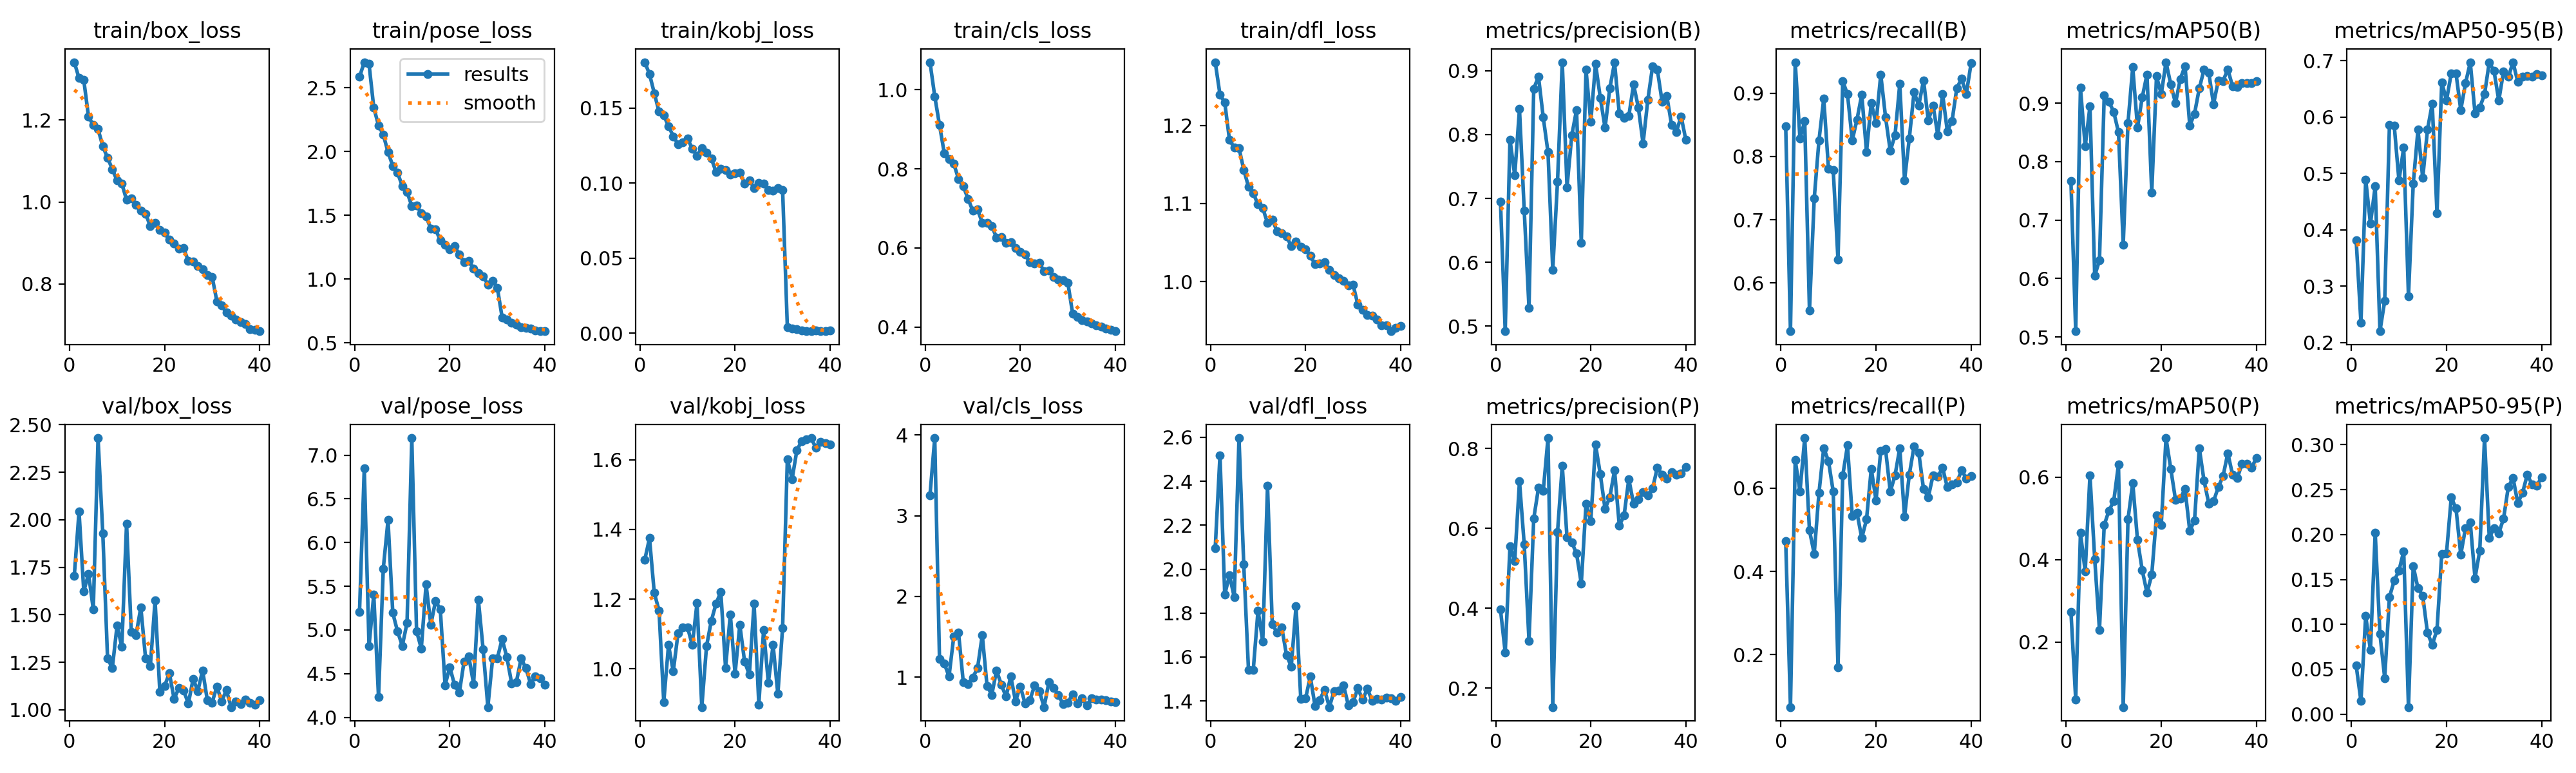

In [43]:
# 7. Losses and validation metrics (val = agreement with ViTPose labels on 2 unseen training blocks)
import pandas as pd
from IPython.display import Image, display
res = pd.read_csv(RUNS / NAME / 'results.csv'); res.columns = [c.strip() for c in res.columns]
cols = [c for c in res.columns if c in ('epoch', 'train/pose_loss', 'train/kobj_loss', 'val/pose_loss', 'val/kobj_loss',
        'metrics/mAP50(P)', 'metrics/mAP50-95(P)')]
print(res[cols].iloc[::5].to_string(index=False)); print('last:'); print(res[cols].tail(1).to_string(index=False))
display(Image(str(RUNS / NAME / 'results.png')))


## 8. E3 comparison

In [44]:
# 8. E3 (14 hardest held-out frames): agreement with AI visual reference labels, incl. swap-tolerant PCK
E1_PT = RUNS / NAME / 'weights' / 'best.pt'
SETD = Path('/content/e3_set')
for tag, w in (('pretrained', YOLO_PT), ('distilled', DIST_PT), ('e1b', E1_PT)):
    !cd /content/pose_tools && python zero_shot_eval.py --gt "{E3_REF}" --images "{SETD}/images" --manifest "{SETD}/manifest.csv" --split e3 --boxes-from-manifest --yolo-pose "{w}" --out "{E1}/e3_{tag}.csv"
e3 = pd.concat([pd.read_csv(E1 / f'e3_{t}.csv').assign(model=t) for t in ('pretrained', 'distilled', 'e1b')])
e3.to_csv(E1 / 'e3_comparison.csv', index=False)
print('E3: AGREEMENT WITH AI REFERENCE LABELS (ai_visual_review_unverified) - NOT ACCURACY')
print(e3.set_index('model').T.to_string())


14 frames, split=e3, group=all
{'model': 'yolo11s-pose', 'frames': 14, 'no_prediction': 0, 'frames_ge3_confident_upper': 1.0, 'latency_ms_median_per_person': 15.6, 'frames_better_with_lr_swap': 10, 'PCK@0.05_upper': 0.068, 'PCK@0.1_upper': 0.176, 'PCK@0.2_upper': 0.243, 'PCK@0.05_all': 0.054, 'PCK@0.1_all': 0.146, 'PCK@0.2_all': 0.315, 'PCK@0.05_upper_swaptol': 0.108, 'PCK@0.1_upper_swaptol': 0.311, 'PCK@0.2_upper_swaptol': 0.541, 'PCK@0.05_all_swaptol': 0.185, 'PCK@0.1_all_swaptol': 0.4, 'PCK@0.2_all_swaptol': 0.608}
wrote /content/drive/MyDrive/pose_baseline/e1/e3_pretrained.csv
14 frames, split=e3, group=all
{'model': 'best', 'frames': 14, 'no_prediction': 0, 'frames_ge3_confident_upper': 1.0, 'latency_ms_median_per_person': 21.9, 'frames_better_with_lr_swap': 4, 'PCK@0.05_upper': 0.176, 'PCK@0.1_upper': 0.459, 'PCK@0.2_upper': 0.703, 'PCK@0.05_all': 0.123, 'PCK@0.1_all': 0.354, 'PCK@0.2_all': 0.592, 'PCK@0.05_upper_swaptol': 0.216, 'PCK@0.1_upper_swaptol': 0.581, 'PCK@0.2_upper_swa

## 9. Test-27 comparison

In [45]:
# 9. Test-27 (held-out): agreement with the TEACHER (ViTPose references) - shows how well the student copies it
ASET = Path('/content/pose_annotation_set_v2')
for tag, w in (('pretrained', YOLO_PT), ('distilled', DIST_PT), ('e1b', E1_PT)):
    !cd /content/pose_tools && python zero_shot_eval.py --gt "{T27_REF}" --images "{ASET}/images" --manifest "{ASET}/manifest.csv" --split real_val --yolo-pose "{w}" --out "{E1}/t27_{tag}.csv"
t27 = pd.concat([pd.read_csv(E1 / f't27_{t}.csv').assign(model=t) for t in ('pretrained', 'distilled', 'e1b')])
t27.to_csv(E1 / 't27_comparison.csv', index=False)
print('TEST-27: AGREEMENT WITH ViTPose TEACHER - NOT ACCURACY')
print(t27.set_index('model').T.to_string())


27 frames, split=real_val, group=all
{'model': 'yolo11s-pose', 'frames': 27, 'no_prediction': 5, 'frames_ge3_confident_upper': 0.815, 'latency_ms_median_per_person': 14.5, 'frames_better_with_lr_swap': 5, 'PCK@0.05_upper': 0.2, 'PCK@0.1_upper': 0.325, 'PCK@0.2_upper': 0.4, 'PCK@0.05_all': 0.173, 'PCK@0.1_all': 0.283, 'PCK@0.2_all': 0.376, 'PCK@0.05_upper_swaptol': 0.25, 'PCK@0.1_upper_swaptol': 0.392, 'PCK@0.2_upper_swaptol': 0.517, 'PCK@0.05_all_swaptol': 0.211, 'PCK@0.1_all_swaptol': 0.333, 'PCK@0.2_all_swaptol': 0.439}
wrote /content/drive/MyDrive/pose_baseline/e1/t27_pretrained.csv
27 frames, split=real_val, group=all
{'model': 'best', 'frames': 27, 'no_prediction': 0, 'frames_ge3_confident_upper': 0.741, 'latency_ms_median_per_person': 18.9, 'frames_better_with_lr_swap': 5, 'PCK@0.05_upper': 0.225, 'PCK@0.1_upper': 0.417, 'PCK@0.2_upper': 0.617, 'PCK@0.05_all': 0.173, 'PCK@0.1_all': 0.321, 'PCK@0.2_all': 0.519, 'PCK@0.05_upper_swaptol': 0.25, 'PCK@0.1_upper_swaptol': 0.442, 'PCK@0

## 10. Lower-body confidence check

In [46]:
# 10. Collapse check: mean keypoint confidence on the 27 + 14 held-out frames (did hips/knees/ankles survive?)
import numpy as np, csv, cv2
from ultralytics import YOLO
sys.path.insert(0, '/content/pose_tools')
from pose_common import COCO17, iou
frames = []
for setd, split in ((ASET, 'real_val'), (SETD, 'e3')):
    for r in csv.DictReader(open(setd / 'manifest.csv')):
        if r['split'] == split:
            frames.append((setd / r['image'], tuple(float(r[k]) for k in ('x1', 'y1', 'x2', 'y2'))))
def mean_conf(w):
    m = YOLO(str(w)); out = []
    for p, box in frames:
        r = m.predict(str(p), verbose=False)[0]
        if r.keypoints is None or len(r.boxes) == 0:
            out.append(np.zeros(17)); continue
        ious = [iou(tuple(b), box) for b in r.boxes.xyxy.cpu().numpy()]; i = int(np.argmax(ious))
        out.append(r.keypoints.conf[i].cpu().numpy() if ious[i] >= 0.3 else np.zeros(17))
    return np.array(out).mean(0)
cp, cd, ce = mean_conf(YOLO_PT), mean_conf(DIST_PT), mean_conf(E1_PT)
print(f'{len(frames)} held-out frames. mean keypoint confidence:')
print(f'{"keypoint":16s} pretrained  distilled  e1b')
for k, n in enumerate(COCO17):
    print(f'{n:16s} {cp[k]:.2f}        {cd[k]:.2f}       {ce[k]:.2f}')
print(f'{"lower body mean":16s} {cp[11:].mean():.2f}        {cd[11:].mean():.2f}       {ce[11:].mean():.2f}')


76 held-out frames. mean keypoint confidence:
keypoint         pretrained  distilled  e1b
nose             0.25        0.35       0.79
left_eye         0.17        0.56       0.80
right_eye        0.16        0.57       0.80
left_ear         0.33        0.28       0.73
right_ear        0.31        0.31       0.72
left_shoulder    0.77        0.74       0.85
right_shoulder   0.74        0.75       0.85
left_elbow       0.72        0.65       0.78
right_elbow      0.69        0.69       0.80
left_wrist       0.65        0.59       0.73
right_wrist      0.63        0.62       0.78
left_hip         0.79        0.50       0.89
right_hip        0.79        0.51       0.89
left_knee        0.73        0.52       0.88
right_knee       0.73        0.52       0.87
left_ankle       0.64        0.51       0.85
right_ankle      0.64        0.51       0.85
lower body mean  0.72        0.51       0.87


Paste cells 4, 5 and 7-10. E1 is a success only if it beats the distilled model on E3 (especially PCK@0.1 and swap-tolerant scores) **and** cell 10 shows no lower-body confidence collapse. All numbers are agreement, not accuracy.